In [ ]:

import pandas as pd

#1. Load your original dataset
df_original = pd.read_csv("/content/drive/MyDrive/Pandas_Dataset/AI_Usage_and_Impact_on_Students_and_Professionals.csv")
#2. Create a safe, independent copy to work on
df_cleaned = df_original.copy()

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Pandas_Dataset/AI_Usage_and_Impact_on_Students_and_Professionals.csv'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#------------------------------Data Exploration-------------------------------------------------------
#Verify the Data columns and rows
print("Dataset shape:", df_cleaned.shape)
#------------------------------------------------
# Display the first rows
print("Display First Rows:", df_cleaned.head())
#------------------------------------------------
# Display the tail rows
print("Display First Rows:", df_cleaned.tail())
#------------------------------------------------
# Know the Column List
print("\nColumn names:")
print(df_cleaned.columns.tolist())
#------------------------------------------------
#Get information from the dataset cleaned
df_cleaned.info()
#-------------------------------------------------
# Describe the Dataset values -Columns & Rows
df_cleaned.describe()
#-------------------------------------------------
# Know the Data types :
df_cleaned.dtypes
#-------------------------------------------------
#------------------------------Data Exploration Completed-------------------------------------------------------

Dataset shape: (300, 19)
Display First Rows:   User_ID Age  Gender         Country     User_Type Education_Level  \
0   U0269  30    Male  United Kingdom  Professional        Master's   
1   U0217  30    Male   United States  Professional      Bachelor's   
2   U0152  17    Male          Canada       Student             NaN   
3   U0264  35  FEMALE          Brazil  Professional      Bachelor's   
4   U0263  19  Female          Canada       Student   Undergraduate   

                                        Profession Monthly_Income  \
0                                 Business Analyst           5421   
1                      Customer Support Specialist           8903   
2                         Computer Science Student            402   
3  Desenvolvedora de Software / Software Developer           1367   
4                                  Biology Student            438   

         AI_Tool        AI_Purpose AI_Usage_Hours_Per_Day  \
0        ChatGPT       Office Work                  

,0
User_ID,object
Age,object
Gender,object
Country,object
User_Type,object
Education_Level,object
Profession,object
Monthly_Income,object
AI_Tool,object
AI_Purpose,object


In [ ]:
#----------------------------------------------Data Cleaning-----------------------------------------------------------#
#$$$$ Exploring Missing Values , Mixed Data Types & Convert to Numbers,Standardize Text & Categorical Data  & Duplicates$$$#
# Explore and Handling Missing Values
# Gender,country 10 Records,Education_level -13 records, Profession-15 Records, Monthly_income-10 Records,
#AI_tool -11 records, Tasks_performed-1 Records,Monthly AI cost -12 records,Productivity_score- 16,Accuracy_ratio-15 , satisfication_score-7,
#time_saved_per_weeks-10,Work or study hrs per day -9, Would_recommeded-5
#------------------------------------------------------------------------------------------------------------------------
#Mixed Data Types & Convert to Numbers,Standardize Text & Categorical Data
#Work_or_Study_Hours_Per_Day,Time_Saved_Hours_Per_Week,AI_Usage_Hours_Per_Day, Age- hrs, yrs  , Monthly_AI_Cost,Monthly_Income-$ , AI-tool- gap in words,Education_Level-lower uppercase
#Country - lower , upper case , Gender - Messy
#------------------------------------------------------------------------------------------------------------------------
# STEP 2: Handle Missing Values for Text & Categories
# ==========================================
# Categorical_columns = ['Gender', 'Country', 'Education_Level', 'Profession', 'AI_Tool', 'AI_Purpose', 'Tasks_Performed']
# for columns in Categorical_columns:
#     df_cleaned[columns] = df_cleaned[columns].fillna('Unknown')

# df_cleaned['Would_Recommend'] = df_cleaned['Would_Recommend'].fillna('Unknown')
# print (df_cleaned[['Gender', 'Country', 'Education_Level', 'Profession', 'AI_Tool', 'AI_Purpose', 'Tasks_Performed']].isnull().sum())
# #-------------------------------------------------------------------------------------------------------------------------
# # STEP 3: Clean and Convert Numerical Columns (Median Fill)
# # ==========================================
# numerical_columns = [
#     'Monthly_Income', 'AI_Usage_Hours_Per_Day',
#     'Monthly_AI_Cost', 'Productivity_Score', 'Accuracy_Rating',
#     'Satisfaction_Score', 'Time_Saved_Hours_Per_Week',
#     'Work_or_Study_Hours_Per_Day'
# ]

# for columns in numerical_columns:
#     # 1. Strip text strings like 'yrs' or 'hrs' and convert to numeric
#     df_cleaned[columns] = pd.to_numeric(
#         df_cleaned[columns].astype(str).str.replace('yrs|hrs|$', '', case=False).str.strip(),errors='coerce'
#     )
#     # 2. Fill missing values with the median
#     middle_value = df_cleaned[columns].median()
#     df_cleaned[columns] = df_cleaned[columns].fillna(middle_value)
# print('Handled Missing Values for Numerical Columns','\n',  df_cleaned[[ 'Monthly_Income', 'AI_Usage_Hours_Per_Day',
#     'Monthly_AI_Cost', 'Productivity_Score', 'Accuracy_Rating',
#     'Satisfaction_Score', 'Time_Saved_Hours_Per_Week',
#     'Work_or_Study_Hours_Per_Day']].isnull().sum())
#---------------------------------------------------------------------------------------------------------------------------------------
# STEP 4: Clean 'Age' and Convert to Integer
# ==========================================
# 1. Clean string characters ('yrs') and convert to numeric
# df_cleaned['Age'] = pd.to_numeric(
#     df_cleaned['Age'].astype(str).str.replace('yrs', '', case=False).str.strip(),errors='coerce'
# )

# # 2. Fill missing ages with the median age
# middle_age = df_cleaned['Age'].median()
# df_cleaned['Age'] = df_cleaned['Age'].fillna(middle_age)

# # 3. Safely convert Age into clean integers (int64)
# df_cleaned['Age'] = df_cleaned['Age'].astype(int)
# print(df_cleaned['Age'].dtypes,'\n',df_cleaned['Age'].isnull().sum(),'\n',df_cleaned['Age'].head())
#--------------------------------------------------------------------------------------------------------------------------------
# STEP 5: Standardize Text (e.g., Gender)
# ==========================================
# df_cleaned['Gender'] = df_cleaned['Gender'].astype(str).str.lower().str.strip()
# df_cleaned['Gender'] = df_cleaned['Gender'].replace({
#     'm': 'male',
#     'f': 'female'
# })
print('Standardize Text are ','\n',df_cleaned['Gender'].unique(),'\n Null_Values\n',df_cleaned['Gender'].isnull().sum(),'\n Display the values\n', df_cleaned['Gender'].head())
#---------------------------------------------------------------------------------------------------------------------------------------------




Standardize Text are  
 ['male' 'female' 'unknown' 'other' 'non-binary'] 
 Null_Values
 0 
 Display the values
 0      male
1      male
2      male
3    female
4    female
Name: Gender, dtype: object


In [ ]:
#Clearing out the Messy values present in AI_Tool Column
# df_cleaned['AI_Tool'] = df_cleaned['AI_Tool'].replace({
#     'chatgpt': 'ChatGPT',
#     'Chatgpt': 'ChatGPT',
#     'Chat GPT':'ChatGPT',
#     'gemini': 'Google Gemini',
#     'Gemini': 'Google Gemini',
#     'copilot': 'Microsoft Copilot',
#     'Copilot': 'Microsoft Copilot',
#     'claude': 'Claude'
# })
# #Verify your unique values to make sure they are fully cleaned!
# print('Standardize Text are ','\n',df_cleaned['AI_Tool'].unique(),'\n Null_Values\n',df_cleaned['AI_Tool'].isnull().sum(),'\n Display the values\n', df_cleaned['AI_Tool'].head())
# #-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
# #Capitalize any remaining string issues in Country Column
# df_cleaned['Country'] = df_cleaned['Country'].str.title()

# 4. Verify your unique values to check how clean it looks now!
# print('Standardize Text are ','\n',df_cleaned['Country'].unique(),'\n Null_Values\n',df_cleaned['Country'].isnull().sum(),'\n Display the values\n', df_cleaned['Country'].head())

#-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

#Clearing out the Messy values and duplicated ,capitalize values  present in Education_Level Column

# df_cleaned['Education_Level'] = df_cleaned['Education_Level'].replace({
#     'high school': 'High School',
#     'HS': 'High School',
#     'Bachelors': "Bachelor's",
#     'BA/BSc': "Bachelor's",
#     "bachelor's degree": "Bachelor's",
#     'undergrad': 'Undergraduate',
#     'Masters': "Master's",
#     'MA/MSc': "Master's",
#     "master's degree": "Master's",
#     'Ph.D.': 'PhD'
# })
#Verify your unique values to make sure they are fully cleaned!
print('Standardize Text are ','\n',df_cleaned['Education_Level'].unique(),'\n Null_Values\n',df_cleaned['Education_Level'].isnull().sum(),'\n Display the values\n', df_cleaned['Education_Level'].head())



Standardize Text are  
 ["Master's" "Bachelor's" 'Unknown' 'Undergraduate' 'High School' 'Diploma'
 'PhD'] 
 Null_Values
 0 
 Display the values
 0         Master's
1       Bachelor's
2          Unknown
3       Bachelor's
4    Undergraduate
Name: Education_Level, dtype: object


In [ ]:
# STEP 6: Verify Your Cleaned Dataset
# ==========================================
print("--- Cleaning Complete! ---")
print(f"Data type of Age: {df_cleaned['Age'].dtype}")
print(f"Total remaining missing values across dataset:\n{df_cleaned.isnull().sum()}")

--- Cleaning Complete! ---
Data type of Age: int64
Total remaining missing values across dataset:
User_ID                        0
Age                            0
Gender                         0
Country                        0
User_Type                      0
Education_Level                0
Profession                     0
Monthly_Income                 0
AI_Tool                        0
AI_Purpose                     0
AI_Usage_Hours_Per_Day         0
Tasks_Performed                0
Monthly_AI_Cost                0
Productivity_Score             0
Accuracy_Rating                0
Satisfaction_Score             0
Time_Saved_Hours_Per_Week      0
Work_or_Study_Hours_Per_Day    0
Would_Recommend                0
dtype: int64


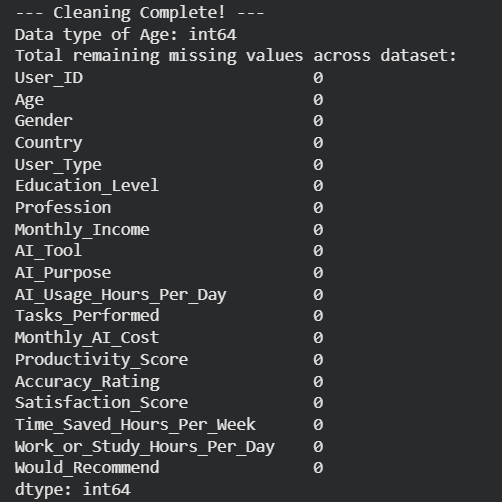

In [ ]:
df_cleaned['Education_Level'].unique()


array(["Master's", "Bachelor's", 'Unknown', 'Undergraduate',
       'High School', 'Diploma', 'high school', 'PhD', 'BA/BSc', 'MA/MSc',
       'Ph.D.', 'Masters', "master's degree", "bachelor's degree",
       'undergrad', 'Bachelors', 'HS'], dtype=object)

In [ ]:
#-------------------------------------------Handling Duplicates--------------------------------------------------------------------------------------------------
# Step 7: Handled Duplicates in User_id
#USER_ID- 12 records with exaclty same rows across the table -- Shown in the below image
#---- Note: That is why we are going to drop these duplicates in the below code
#Check how many duplicate User_IDs exist before dropping
# print("Duplicate User_IDs count before dropping the rows:\n", df_cleaned['User_ID'].duplicated().sum(),'\nDuplicated Entries of Columns:\n',df_cleaned.duplicated(subset=df_cleaned.columns.tolist(),keep=False).sum())

#-----------------------------------------------------------------------------------------------------------------------------------
#Drop duplicate rows based on 'User_ID', keeping the first occurrence

print('Before Dropped Rows:\n',len(df_original)) #--- 300 rows

# df_cleaned = df_cleaned.drop_duplicates(subset=['User_ID'], keep='first')

print('After Dropped Rows:\n',len(df_cleaned)) #--- 288 rows now

Before Dropped Rows:
 300
After Dropped Rows:
 288


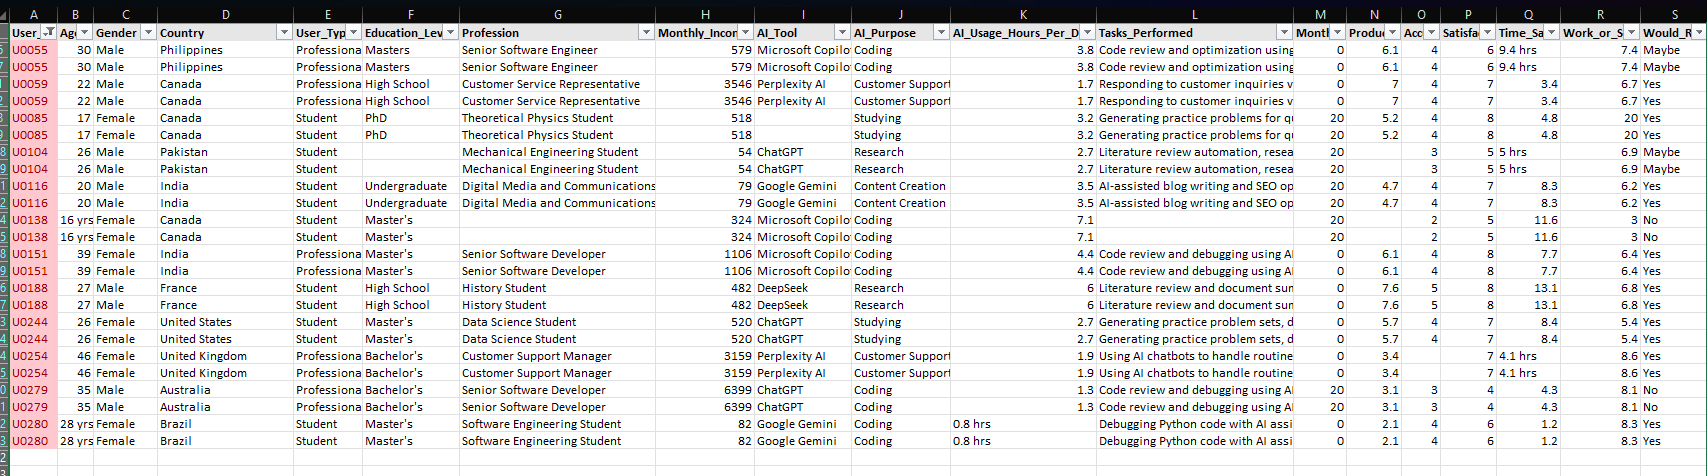

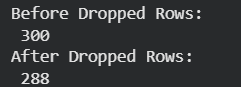

In [ ]:
# 3. Print out the  final results for confirmation of cleaned dataset
print(f"Successfully removed {len(df_original) - len(df_cleaned)} duplicate rows!=0")
print(f"New total row count in df_cleaned: {len(df_cleaned)}")

Successfully removed 12 duplicate rows!=0
New total row count in df_cleaned: 288


In [ ]:
# 1. First, save your cleaned dataframe as a new CSV file
# df_cleaned.to_csv('AI_Usage_Impact_On_Students_&_Professionals_Cleaned_Dataset.csv', index=False)
df_cleaned.shape


(288, 19)

In [ ]:
# # 2. Trigger the download prompt in Google Colab
from google.colab import files
files.download('AI_Usage_Impact_On_Students_&_Professionals_Cleaned_Dataset.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>